In [16]:
# %pip install pandas matplotlib seaborn scikit-learn mlxtend statsmodels pmdarima chronos-forecasting

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import mean_absolute_error, mean_squared_error, silhouette_score, davies_bouldin_score, calinski_harabasz_score
from mlxtend.frequent_patterns import fpgrowth, association_rules
from mlxtend.preprocessing import TransactionEncoder
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.statespace.sarimax import SARIMAX
from pmdarima import auto_arima
import torch
from chronos import ChronosPipeline
from sklearn.preprocessing import StandardScaler
from scipy.cluster.hierarchy import dendrogram, linkage, fcluster

# Data Loading and Cleaning

In [18]:
df = pd.read_csv('data/transactions.csv')
lookup = pd.read_csv('data/operation_statuses.csv')

In [19]:
df.shape

(1000000, 7)

In [20]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 7 columns):
 #   Column             Non-Null Count    Dtype
---  ------             --------------    -----
 0   Id                 1000000 non-null  int64
 1   OrgId              1000000 non-null  int64
 2   TransactionTypeId  1000000 non-null  int64
 3   Transaction_Date   1000000 non-null  str  
 4   OperationStatusId  1000000 non-null  int64
 5   CardlNumber        907132 non-null   str  
 6   PersonId           1000000 non-null  int64
dtypes: int64(5), str(2)
memory usage: 53.4 MB


In [21]:
df.head()

,Id,OrgId,TransactionTypeId,Transaction_Date,OperationStatusId,CardlNumber,PersonId
0,531993,132,1,4/18/2023 8:10,20,NaN,101093
1,532002,132,1,4/18/2023 8:13,20,NaN,101093
2,532007,132,1,4/18/2023 8:18,20,NaN,101093
3,532012,132,1,4/18/2023 8:19,20,NaN,101093
4,532013,21,1,4/18/2023 8:19,20,NaN,1749567


In [22]:
df['Transaction_Date'] = pd.to_datetime(df['Transaction_Date'])

In [23]:
df = df.merge(lookup[['OperationStatusId', 'Name']], on='OperationStatusId', how='left')
df.rename(columns={'Name': 'StatusName'}, inplace=True)

In [24]:
df.isnull().sum()

Id                       0
OrgId                    0
TransactionTypeId        0
Transaction_Date         0
OperationStatusId        0
CardlNumber          92868
PersonId                 0
StatusName               0
dtype: int64

In [25]:
df['CardlNumber'] = df['CardlNumber'].fillna('No Card')

In [26]:
df['Id'].duplicated().sum()

np.int64(23845)

In [27]:
dupes = df[df['Id'].duplicated(keep=False)].sort_values('Id')
dupes.head(20)

,Id,OrgId,TransactionTypeId,Transaction_Date,OperationStatusId,CardlNumber,PersonId,StatusName
92618,532418,70,1,2024-09-28 05:58:00,20,1FD1A6C0CC6FF43700000060D4A8,474997,Refused
862758,532418,58,1,2023-04-18 11:51:00,10,No Card,1162389,Acknowledged
20,534447,79,1,2023-04-19 20:19:00,20,No Card,1457535,Refused
92739,534447,49,2,2024-09-28 06:33:00,20,1FD1A6C0CC6FF437000000609A3F,2384794,Refused
92747,534624,49,2,2024-09-28 06:36:00,20,1FD1A6C0CC6FF4370000005E3FAE,1885183,Refused
24641,534624,79,1,2023-04-20 04:51:00,20,No Card,1758456,Refused
24642,534899,80,1,2023-04-20 08:21:00,20,1FD1A6C0CC6FF4370000002E127C,426782,Refused
92766,534899,43,2,2024-09-28 06:40:00,20,1FD1A6C0CC6FF4370000004CD5A7,459787,Refused
28,535876,79,1,2023-04-20 20:05:00,20,No Card,333626,Refused
92824,535876,70,1,2024-09-28 06:54:00,20,1FD1A6C0CC6FF43700000060A61F,2656311,Refused


In [28]:
df['Year'] = df['Transaction_Date'].dt.year
df['Month'] = df['Transaction_Date'].dt.month
df['Day'] = df['Transaction_Date'].dt.day
df['Hour'] = df['Transaction_Date'].dt.hour
df['DayOfWeek'] = df['Transaction_Date'].dt.dayofweek

In [29]:
df.head()

,Id,OrgId,TransactionTypeId,Transaction_Date,OperationStatusId,CardlNumber,PersonId,StatusName,Year,Month,Day,Hour,DayOfWeek
0,531993,132,1,2023-04-18 08:10:00,20,No Card,101093,Refused,2023,4,18,8,1
1,532002,132,1,2023-04-18 08:13:00,20,No Card,101093,Refused,2023,4,18,8,1
2,532007,132,1,2023-04-18 08:18:00,20,No Card,101093,Refused,2023,4,18,8,1
3,532012,132,1,2023-04-18 08:19:00,20,No Card,101093,Refused,2023,4,18,8,1
4,532013,21,1,2023-04-18 08:19:00,20,No Card,1749567,Refused,2023,4,18,8,1


# Exploratory Data Analysis

## Monthly Transaction

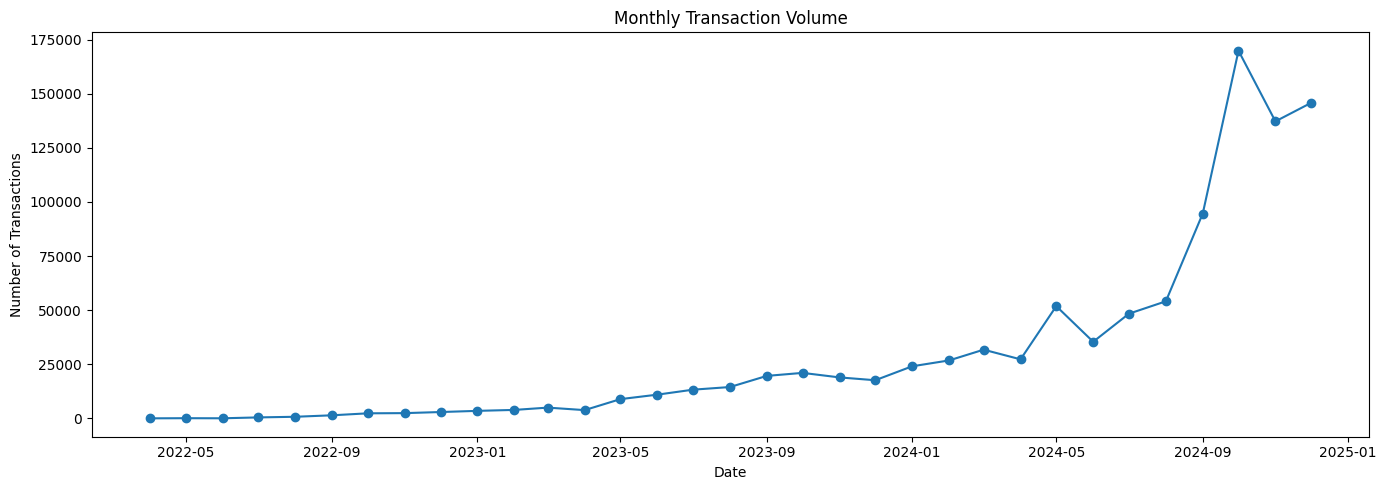

In [89]:
monthly = df.groupby(['Year', 'Month']).size().reset_index(name='Count')
monthly['Date'] = pd.to_datetime(monthly[['Year', 'Month']].assign(day=1))

plt.figure(figsize=(14, 5))
plt.plot(monthly['Date'], monthly['Count'], marker='o')
plt.title('Monthly Transaction Volume')
plt.xlabel('Date')
plt.ylabel('Number of Transactions')
plt.tight_layout()
plt.savefig('assets/monthly_volume.pdf', bbox_inches='tight')
plt.show()

Let's try to analyze the spike in may 2024

In [31]:
apr2024 = df[(df['Year'] == 2024) & (df['Month'] == 4)]

print("=== April 2024 ===")
print(f"Total transactions: {len(apr2024):,}")
print(f"Unique orgs: {apr2024['OrgId'].nunique()}")
print(f"Type distribution:\n{apr2024['TransactionTypeId'].value_counts()}")
print(f"Status distribution:\n{apr2024['OperationStatusId'].value_counts()}")
print(f"Top orgs:\n{apr2024['OrgId'].value_counts().head(5)}")

=== April 2024 ===
Total transactions: 27,325
Unique orgs: 38
Type distribution:
TransactionTypeId
2    18979
1     8346
Name: count, dtype: int64
Status distribution:
OperationStatusId
10    18217
20     9108
Name: count, dtype: int64
Top orgs:
OrgId
49     15794
104     3286
79      2903
43       902
119      723
Name: count, dtype: int64


In [32]:
may2024 = df[(df['Year'] == 2024) & (df['Month'] == 5)]

print("=== May 2024 ===")
print(f"Total transactions: {len(may2024):,}")
print(f"Unique orgs: {may2024['OrgId'].nunique()}")
print(f"Type distribution:\n{may2024['TransactionTypeId'].value_counts()}")
print(f"Status distribution:\n{may2024['OperationStatusId'].value_counts()}")
print(f"Top orgs:\n{may2024['OrgId'].value_counts().head(5)}")

=== May 2024 ===
Total transactions: 51,888
Unique orgs: 41
Type distribution:
TransactionTypeId
2    41980
1     9908
Name: count, dtype: int64
Status distribution:
OperationStatusId
10    51291
20      597
Name: count, dtype: int64
Top orgs:
OrgId
49     37512
104     3497
79      3423
57      1576
43      1158
Name: count, dtype: int64


In [33]:
jun2024 = df[(df['Year'] == 2024) & (df['Month'] == 6)]

print("=== June 2024 ===")
print(f"Total transactions: {len(jun2024):,}")
print(f"Unique orgs: {jun2024['OrgId'].nunique()}")
print(f"Type distribution:\n{jun2024['TransactionTypeId'].value_counts()}")
print(f"Status distribution:\n{jun2024['OperationStatusId'].value_counts()}")
print(f"Top orgs:\n{jun2024['OrgId'].value_counts().head(5)}")

=== June 2024 ===
Total transactions: 35,434
Unique orgs: 39
Type distribution:
TransactionTypeId
2    29237
1     6197
Name: count, dtype: int64
Status distribution:
OperationStatusId
10    35434
Name: count, dtype: int64
Top orgs:
OrgId
49     25998
79      3394
104     2099
57       743
146      535
Name: count, dtype: int64


org 49 is the main reason for spike. Let's analyze it as well

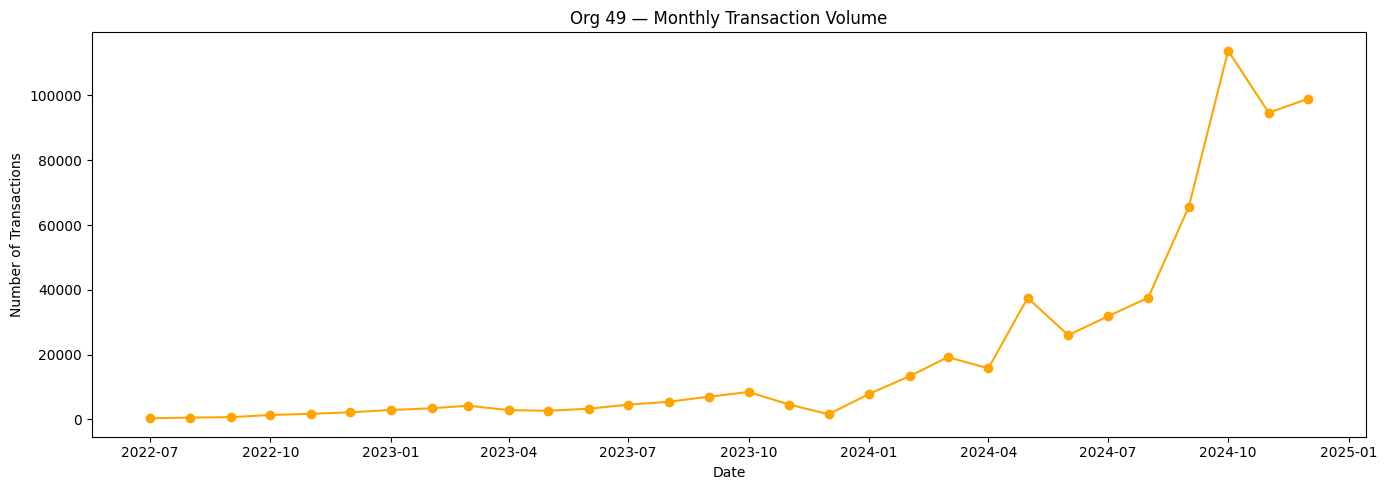

In [90]:
org49 = df[df['OrgId'] == 49].groupby(['Year', 'Month']).size().reset_index(name='Count')
org49['Date'] = pd.to_datetime(org49[['Year', 'Month']].assign(day=1))

plt.figure(figsize=(14, 5))
plt.plot(org49['Date'], org49['Count'], marker='o', color='orange')
plt.title('Org 49 — Monthly Transaction Volume')
plt.xlabel('Date')
plt.ylabel('Number of Transactions')
plt.tight_layout()
plt.savefig('assets/org49_monthly_volume.pdf', bbox_inches='tight')
plt.show()

It looks nearly identical to our monthly distribution chart. So it is a dominant organization on the entire timeline

## Org transaction

In [35]:
org_volume = df.groupby('OrgId').size().reset_index(name='Count').sort_values('Count', ascending=False)
org_volume['percentage'] = org_volume['Count'] / org_volume['Count'].sum() * 100
org_volume.head(20)

,OrgId,Count,percentage
12,49,620445,62.0445
23,70,84128,8.4128
24,79,84081,8.4081
17,57,55313,5.5313
37,104,48129,4.8129
9,43,18604,1.8604
43,119,14522,1.4522
42,118,13918,1.3918
48,127,9292,0.9292
65,146,8494,0.8494


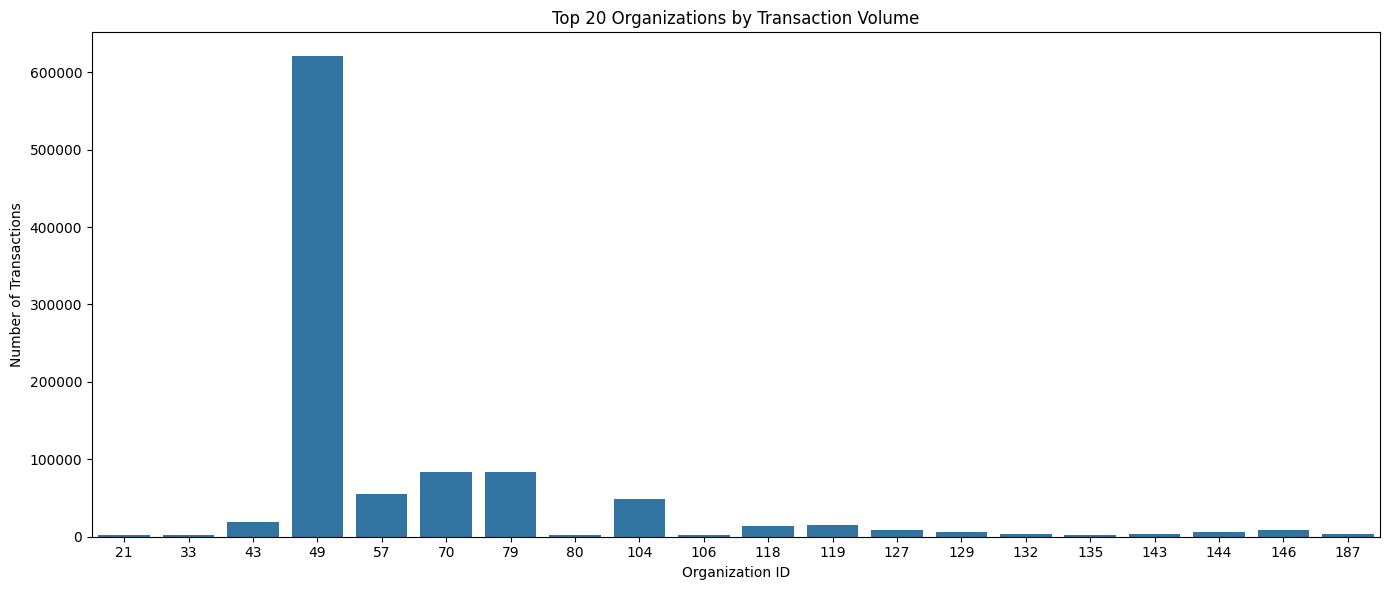

In [91]:
plt.figure(figsize=(14, 6))
sns.barplot(data=org_volume.head(20), x='OrgId', y='Count')
plt.title('Top 20 Organizations by Transaction Volume')
plt.xlabel('Organization ID')
plt.ylabel('Number of Transactions')
plt.tight_layout()
plt.savefig('assets/top20_orgs_volume.pdf', bbox_inches='tight')
plt.show()

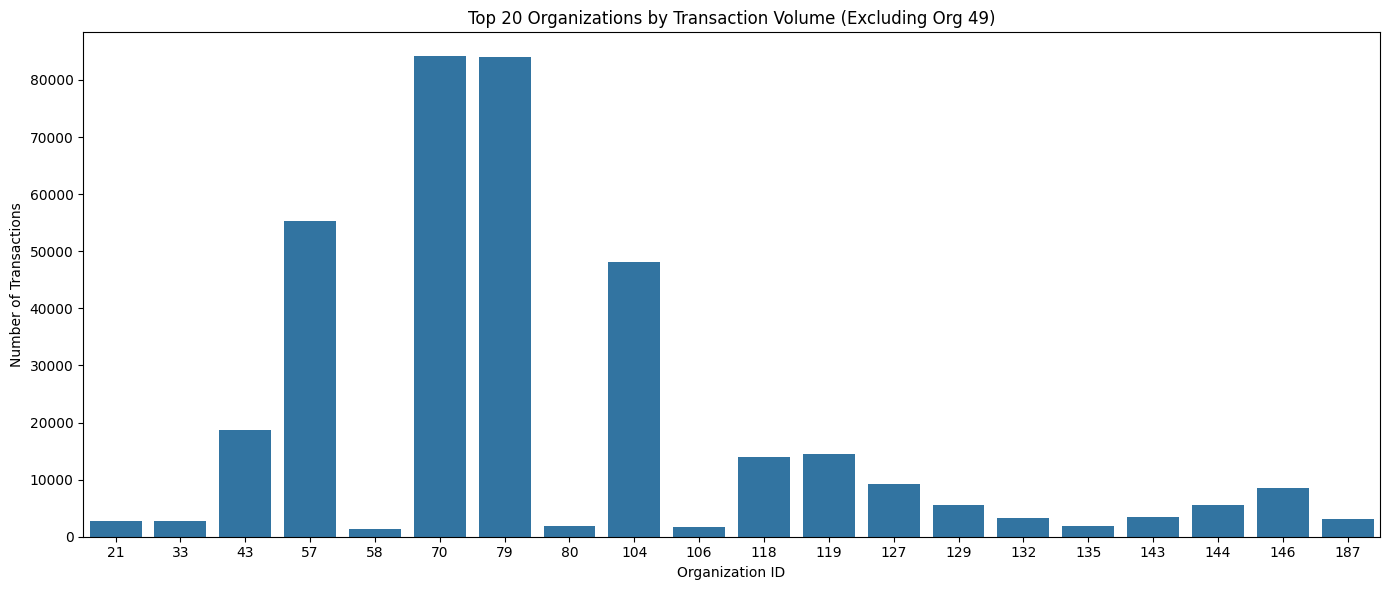

In [92]:
org_volume_ex49 = org_volume[org_volume['OrgId'] != 49]

plt.figure(figsize=(14, 6))
sns.barplot(data=org_volume_ex49.head(20), x='OrgId', y='Count')
plt.title('Top 20 Organizations by Transaction Volume (Excluding Org 49)')
plt.xlabel('Organization ID')
plt.ylabel('Number of Transactions')
plt.tight_layout()
plt.savefig('assets/top20_orgs_volume_ex49.pdf', bbox_inches='tight')
plt.show()

# Customer Segmentation - RF Analysis

In [38]:
reference_date = df['Transaction_Date'].max()
print(f"Reference date: {reference_date}")

Reference date: 2024-12-31 23:56:00


In [39]:
reference_date = df['Transaction_Date'].max()

rf = df.groupby('PersonId').agg(
    LastTransaction=('Transaction_Date', 'max'),
    Frequency=('Id', 'count')
).reset_index()

rf['Recency'] = (reference_date - rf['LastTransaction']).dt.days
rf.drop(columns=['LastTransaction'], inplace=True)
rf.head()

,PersonId,Frequency,Recency
0,4,2,234
1,26,4,27
2,31,4,56
3,34,7,9
4,39,2,99


In [40]:
print(f"\nFrequency value counts (top 10):")
print(rf['Frequency'].value_counts(normalize=True).head(10))


Frequency value counts (top 10):
Frequency
1     0.348488
2     0.218118
3     0.127114
4     0.078542
5     0.049192
6     0.035358
7     0.025023
8     0.019401
9     0.014488
10    0.011142
Name: proportion, dtype: float64


In [41]:
rf['R_Score'] = pd.cut(rf['Recency'], bins=[-1, 30, 90, 180, float('inf')], labels=[4, 3, 2, 1])
rf['F_Score'] = pd.cut(rf['Frequency'], bins=[0, 1, 3, 10, float('inf')], labels=[1, 2, 3, 4])
rf.head()

,PersonId,Frequency,Recency,R_Score,F_Score
0,4,2,234,1,2
1,26,4,27,4,3
2,31,4,56,3,3
3,34,7,9,4,3
4,39,2,99,2,2


In [42]:
def assign_segment(row):
    r = row['R_Score']
    f = row['F_Score']
    if r == 4 and f == 4:
        return 'Champions'
    elif r >= 3 and f >= 3:
        return 'Loyal'
    elif r <= 2 and f >= 3:
        return 'At Risk'
    elif r == 1 and f <= 2:
        return 'Lost'
    else:
        return 'Occasional'
    
rf['Segment'] = rf.apply(assign_segment, axis=1)
rf['Segment'].value_counts()

Segment
Occasional    120364
Loyal          44850
Lost           43011
At Risk        17691
Champions       9590
Name: count, dtype: int64

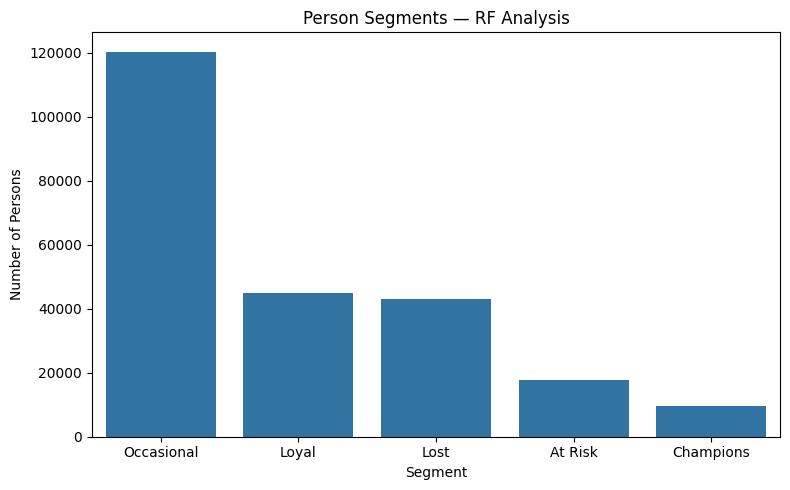

In [93]:
plt.figure(figsize=(8, 5))
sns.countplot(data=rf, x='Segment', order=rf['Segment'].value_counts().index)
plt.title('Person Segments — RF Analysis')
plt.xlabel('Segment')
plt.ylabel('Number of Persons')
plt.tight_layout()
plt.savefig('assets/person_segments.pdf', bbox_inches='tight')
plt.show()

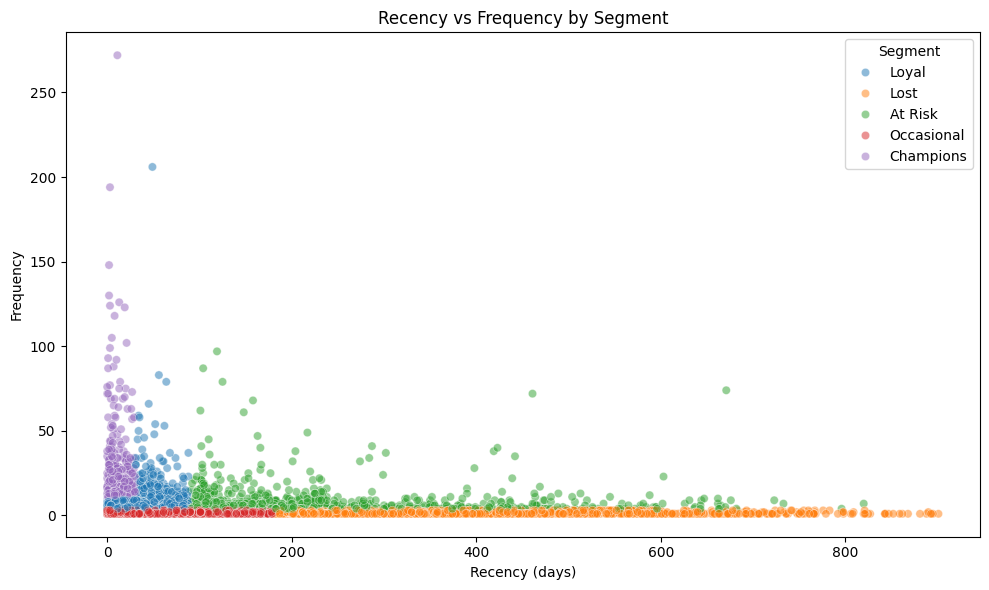

In [115]:
plt.figure(figsize=(10, 6))
sns.scatterplot(data=rf.sample(10000), x='Recency', y='Frequency', hue='Segment', alpha=0.5)
plt.title('Recency vs Frequency by Segment')
plt.xlabel('Recency (days)')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig('assets/recency_vs_frequency.pdf', bbox_inches='tight')
plt.show()

We can also analyze segment distribution per organization

In [45]:
segment_org = df.merge(rf[['PersonId', 'Segment']], on='PersonId', how='left')
org_totals = segment_org.groupby('OrgId').size().reset_index(name='OrgTotal')

top_orgs_per_segment = (
    segment_org.groupby(['Segment', 'OrgId'])
    .size()
    .reset_index(name='Count')
    .merge(org_totals, on='OrgId')
)

top_orgs_per_segment['Pct_of_Org'] = (top_orgs_per_segment['Count'] / top_orgs_per_segment['OrgTotal'] * 100).round(1)
top_orgs_per_segment = (
    top_orgs_per_segment
    .sort_values(['Segment', 'Count'], ascending=[True, False])
    .groupby('Segment')
    .head(5)
)
top_orgs_per_segment

,Segment,OrgId,Count,OrgTotal,Pct_of_Org
8,At Risk,49,95128,620445,15.3
12,At Risk,57,21873,55313,39.5
19,At Risk,79,12422,84081,14.8
28,At Risk,104,7275,48129,15.1
7,At Risk,43,5028,18604,27.0
69,Champions,49,170259,620445,27.4
96,Champions,118,12603,13918,90.6
97,Champions,119,11431,14522,78.7
102,Champions,127,8158,9292,87.8
81,Champions,79,7668,84081,9.1


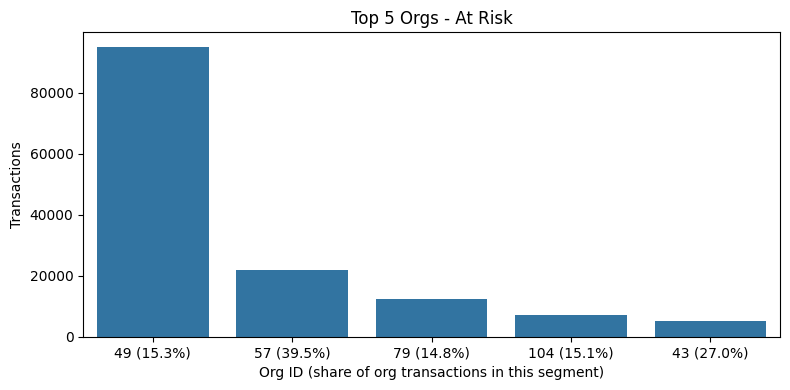

In [95]:
data = top_orgs_per_segment[top_orgs_per_segment['Segment'] == 'At Risk'].copy()
data['Label'] = data['OrgId'].astype(str) + ' (' + data['Pct_of_Org'].astype(str) + '%)'
plt.figure(figsize=(8, 4))
sns.barplot(data=data, x='Label', y='Count')
plt.title('Top 5 Orgs - At Risk')
plt.xlabel('Org ID (share of org transactions in this segment)')
plt.ylabel('Transactions')
plt.tight_layout()
plt.savefig('assets/top5_orgs_at_risk.pdf', bbox_inches='tight')
plt.show()

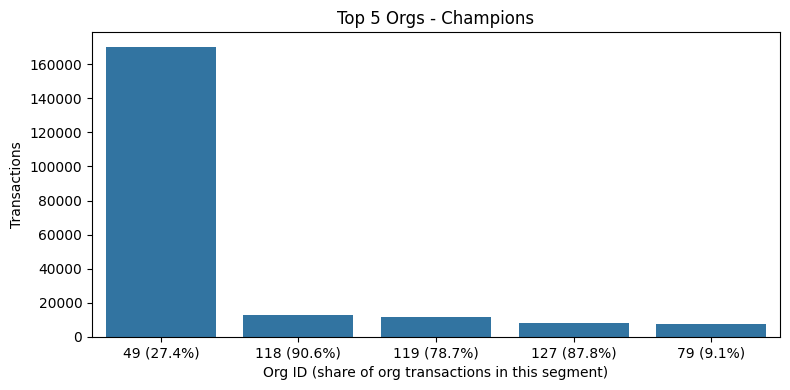

In [96]:
data = top_orgs_per_segment[top_orgs_per_segment['Segment'] == 'Champions'].copy()
data['Label'] = data['OrgId'].astype(str) + ' (' + data['Pct_of_Org'].astype(str) + '%)'
plt.figure(figsize=(8, 4))
sns.barplot(data=data, x='Label', y='Count')
plt.title('Top 5 Orgs - Champions')
plt.xlabel('Org ID (share of org transactions in this segment)')
plt.ylabel('Transactions')
plt.tight_layout()
plt.savefig('assets/top5_orgs_champions.pdf', bbox_inches='tight')
plt.show()

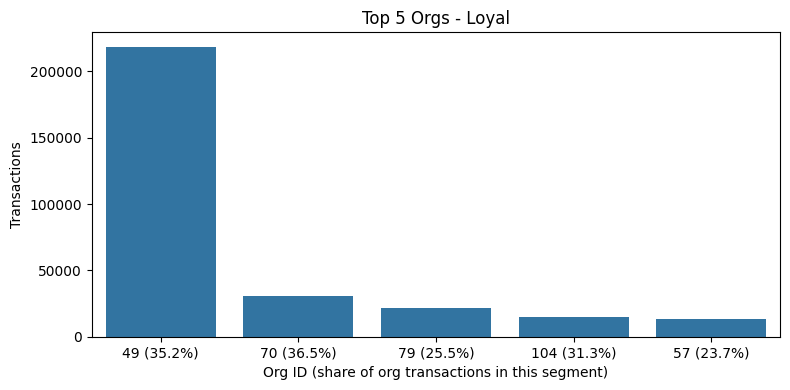

In [97]:
data = top_orgs_per_segment[top_orgs_per_segment['Segment'] == 'Loyal'].copy()
data['Label'] = data['OrgId'].astype(str) + ' (' + data['Pct_of_Org'].astype(str) + '%)'
plt.figure(figsize=(8, 4))
sns.barplot(data=data, x='Label', y='Count')
plt.title('Top 5 Orgs - Loyal')
plt.xlabel('Org ID (share of org transactions in this segment)')
plt.ylabel('Transactions')
plt.tight_layout()
plt.savefig('assets/top5_orgs_loyal.pdf', bbox_inches='tight')
plt.show()

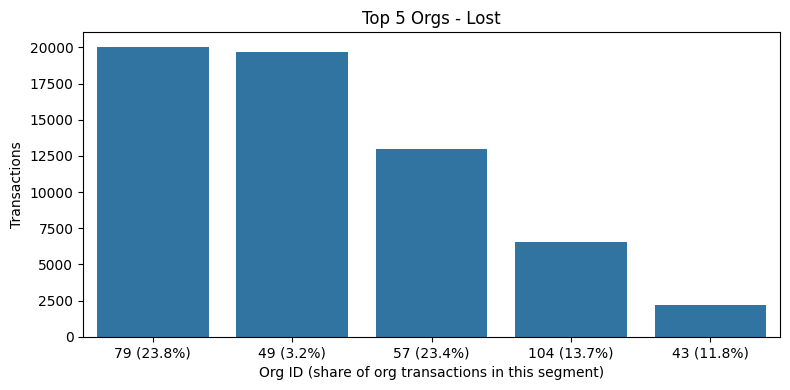

In [98]:
data = top_orgs_per_segment[top_orgs_per_segment['Segment'] == 'Lost'].copy()
data['Label'] = data['OrgId'].astype(str) + ' (' + data['Pct_of_Org'].astype(str) + '%)'
plt.figure(figsize=(8, 4))
sns.barplot(data=data, x='Label', y='Count')
plt.title('Top 5 Orgs - Lost')
plt.xlabel('Org ID (share of org transactions in this segment)')
plt.ylabel('Transactions')
plt.tight_layout()
plt.savefig('assets/top5_orgs_lost.pdf', bbox_inches='tight')
plt.show()

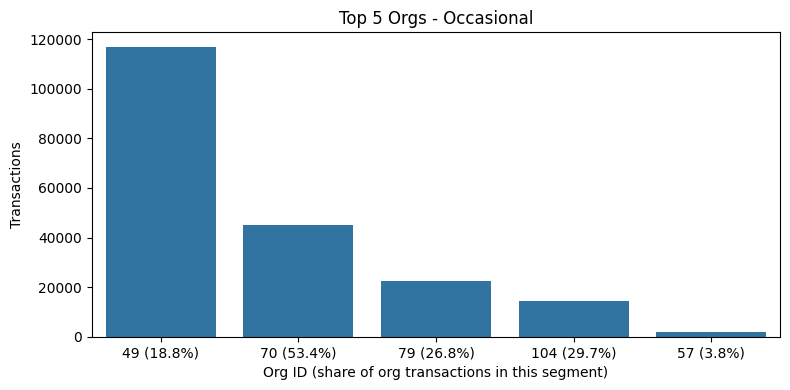

In [99]:
data = top_orgs_per_segment[top_orgs_per_segment['Segment'] == 'Occasional'].copy()
data['Label'] = data['OrgId'].astype(str) + ' (' + data['Pct_of_Org'].astype(str) + '%)'
plt.figure(figsize=(8, 4))
sns.barplot(data=data, x='Label', y='Count')
plt.title('Top 5 Orgs - Occasional')
plt.xlabel('Org ID (share of org transactions in this segment)')
plt.ylabel('Transactions')
plt.tight_layout()
plt.savefig('assets/top5_orgs_occasional.pdf', bbox_inches='tight')
plt.show()

# Organization Co-occurrence Analysis

In [51]:
baskets = df.groupby('PersonId')['OrgId'].apply(lambda x: list(x.unique())).reset_index()
baskets.head()

,PersonId,OrgId
0,4,"[146, 49]"
1,26,"[49, 70]"
2,31,"[49, 70, 43, 104]"
3,34,"[49, 70]"
4,39,"[49, 70]"


In [52]:
te = TransactionEncoder()
te_array = te.fit_transform(baskets['OrgId'])
basket_df = pd.DataFrame(te_array, columns=te.columns_)
basket_df.shape

(235506, 95)

In [53]:
frequent_itemsets = fpgrowth(basket_df, min_support=0.01, use_colnames=True)
frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(len)
frequent_itemsets.sort_values('support', ascending=False)

,support,itemsets,length
0,0.690636,frozenset({49}),1
2,0.295950,frozenset({70}),1
10,0.243556,"frozenset({49, 70})",2
5,0.232219,frozenset({79}),1
3,0.110770,frozenset({104}),1
18,0.088889,"frozenset({49, 79})",2
6,0.071281,frozenset({57}),1
11,0.038092,"frozenset({104, 49})",2
4,0.034649,frozenset({43}),1
19,0.029965,"frozenset({70, 79})",2


In [54]:
rules = association_rules(frequent_itemsets, metric='confidence', min_threshold=0.3)
rules = rules.sort_values('confidence', ascending=False)
rules

,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski
4,"frozenset({104, 70})",frozenset({49}),0.011732,0.690636,0.010063,0.857763,1.241990,1.0,0.001961,2.174992,0.197153,0.014536,0.540228,0.436167
10,"frozenset({70, 79})",frozenset({49}),0.029965,0.690636,0.025477,0.850220,1.231067,1.0,0.004782,2.065449,0.193495,0.036651,0.515844,0.443554
0,frozenset({146}),frozenset({49}),0.015949,0.690636,0.013409,0.840788,1.217411,1.0,0.002395,1.943094,0.181479,0.019345,0.485357,0.430102
2,frozenset({70}),frozenset({49}),0.295950,0.690636,0.243556,0.822965,1.191604,1.0,0.039163,1.747470,0.228385,0.327788,0.427744,0.587810
7,frozenset({43}),frozenset({49}),0.034649,0.690636,0.022522,0.650000,0.941161,1.0,-0.001408,0.883896,-0.060822,0.032047,-0.131355,0.341305
12,"frozenset({57, 79})",frozenset({49}),0.021137,0.690636,0.010280,0.486340,0.704191,1.0,-0.004318,0.602273,-0.300279,0.014654,-0.660376,0.250612
6,"frozenset({104, 79})",frozenset({49}),0.025927,0.690636,0.012220,0.471340,0.682472,1.0,-0.005686,0.585184,-0.323248,0.017350,-0.708864,0.244517
9,frozenset({79}),frozenset({49}),0.232219,0.690636,0.088889,0.382783,0.554246,1.0,-0.071490,0.501223,-0.511600,0.106586,-0.995119,0.255745
11,frozenset({57}),frozenset({49}),0.071281,0.690636,0.027239,0.382141,0.553317,1.0,-0.021990,0.500703,-0.465024,0.037076,-0.997193,0.210791
13,"frozenset({57, 49})",frozenset({79}),0.027239,0.232219,0.010280,0.377397,1.625175,1.0,0.003955,1.233178,0.395453,0.041256,0.189087,0.210833


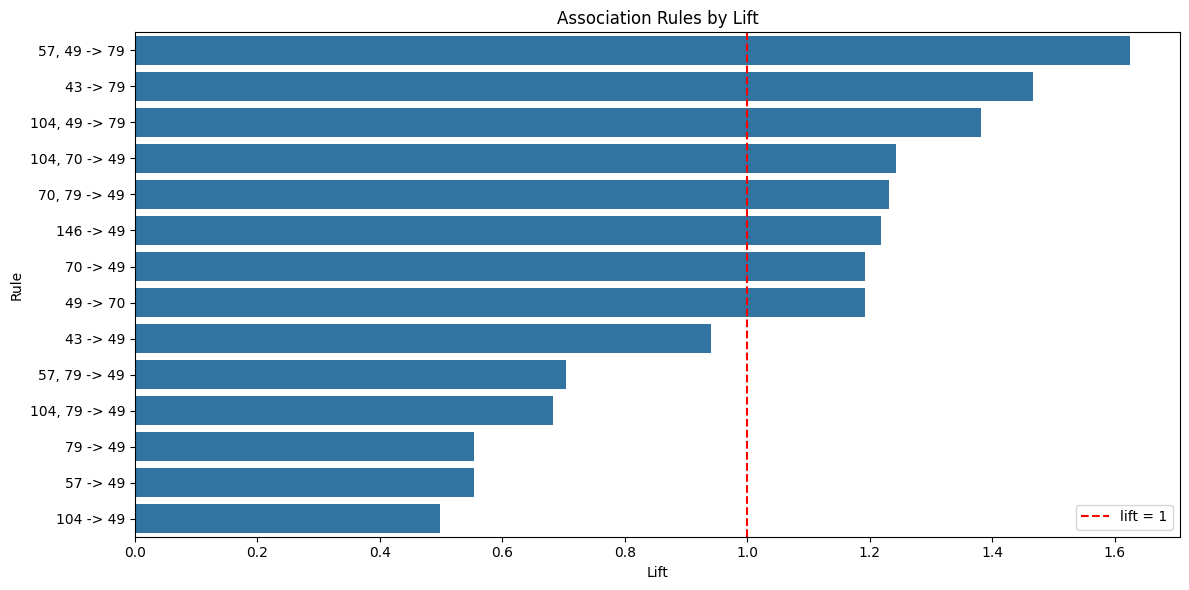

In [101]:
rules['rule'] = rules['antecedents'].apply(lambda x: ', '.join(map(str, x))) + ' -> ' + rules['consequents'].apply(lambda x: ', '.join(map(str, x)))
rules_sorted = rules.sort_values('lift', ascending=False)

plt.figure(figsize=(12, 6))
sns.barplot(data=rules_sorted, x='lift', y='rule')
plt.axvline(x=1, color='red', linestyle='--', label='lift = 1')
plt.title('Association Rules by Lift')
plt.xlabel('Lift')
plt.ylabel('Rule')
plt.legend()
plt.tight_layout()
plt.savefig('assets/association_rules_lift.pdf', bbox_inches='tight')
plt.show()

# Time-Series Analysis & Forecasting

## Analysis

In [56]:
daily = df.groupby(df['Transaction_Date'].dt.date).size().reset_index(name='Count')
daily.columns = ['Date', 'Count']
daily['Date'] = pd.to_datetime(daily['Date'])
daily = daily.set_index('Date').asfreq('D').fillna(0)
daily.head()

,Count
Date,
2022-04-14,1.0
2022-04-15,9.0
2022-04-16,0.0
2022-04-17,0.0
2022-04-18,12.0


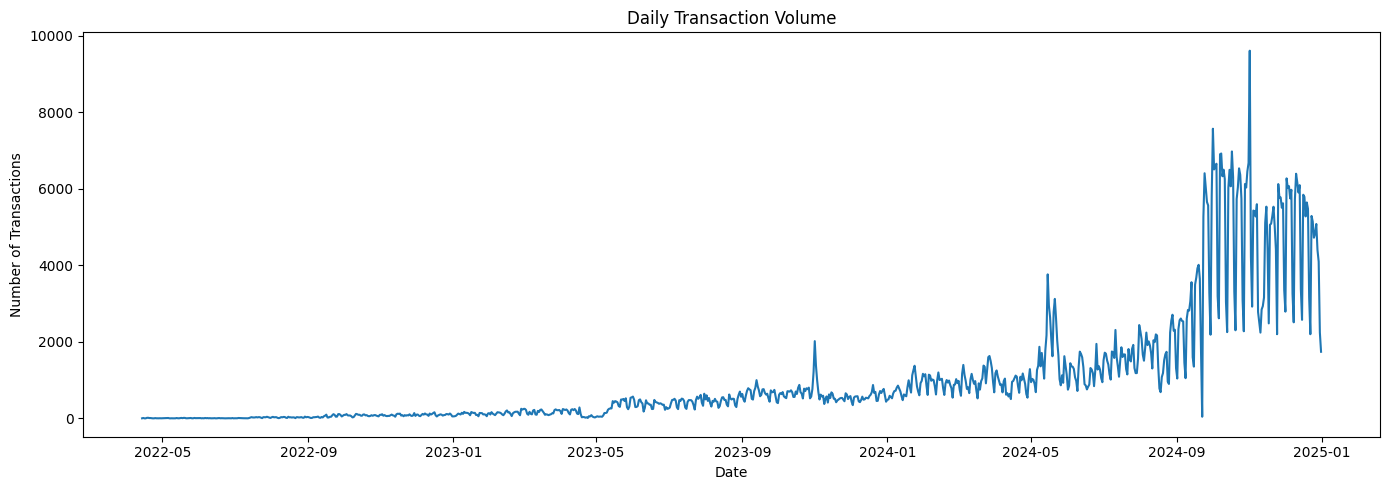

In [102]:
plt.figure(figsize=(14, 5))
plt.plot(daily.index, daily['Count'])
plt.title('Daily Transaction Volume')
plt.xlabel('Date')
plt.ylabel('Number of Transactions')
plt.tight_layout()
plt.savefig('assets/daily_transaction_volume.pdf', bbox_inches='tight')
plt.show()

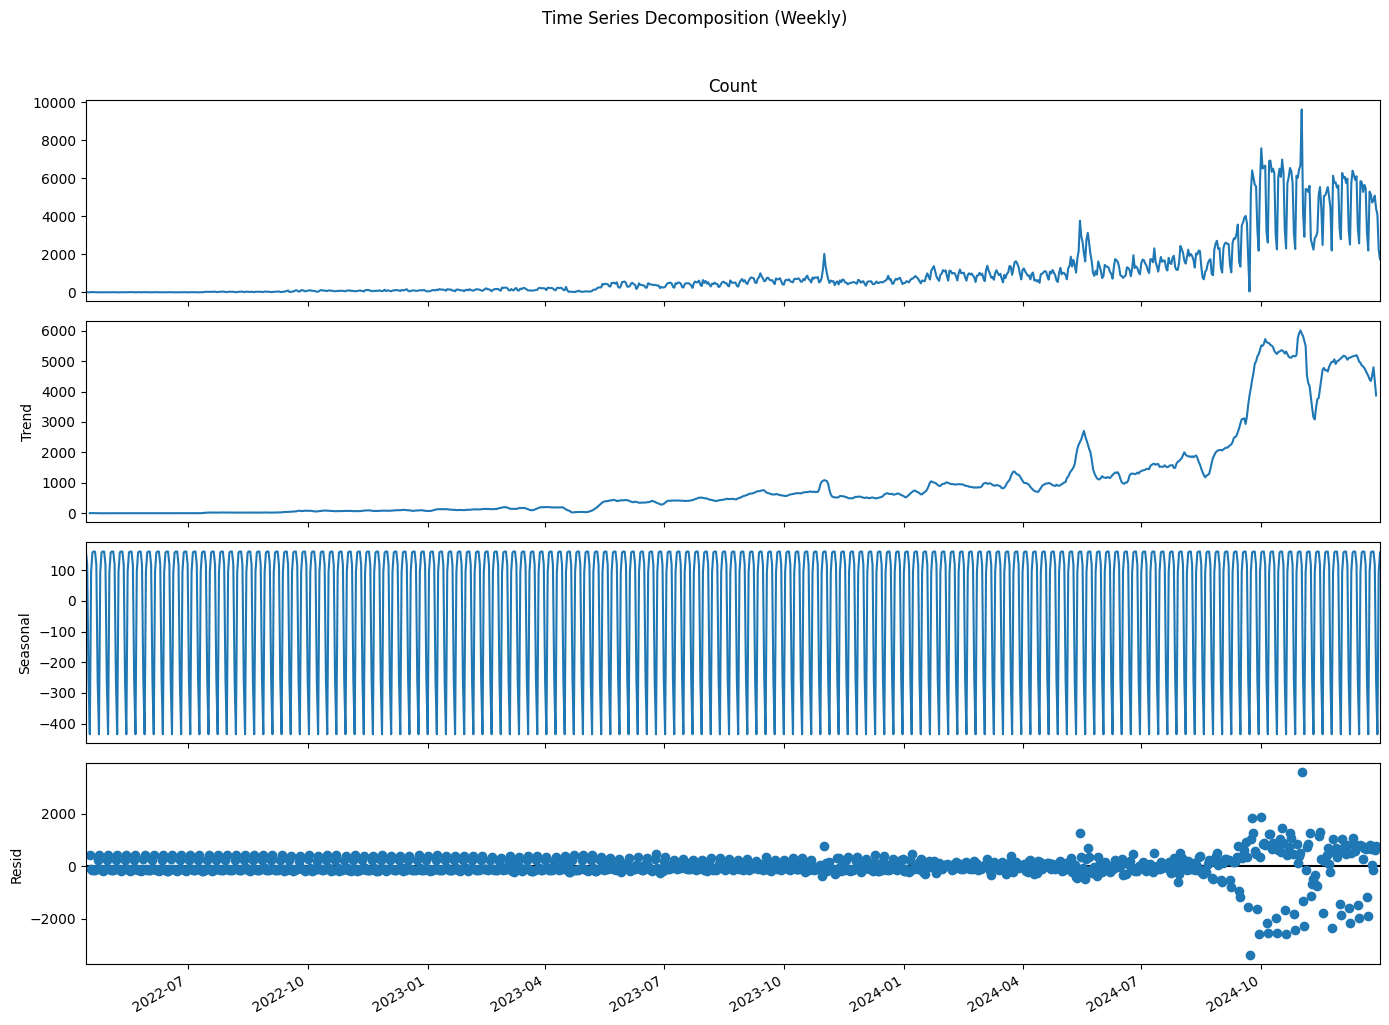

In [103]:
decomposition = seasonal_decompose(daily['Count'], model='additive', period=7)
fig = decomposition.plot()
fig.set_size_inches(14, 10)
fig.autofmt_xdate()
plt.suptitle('Time Series Decomposition (Weekly)', y=1.02)
plt.tight_layout()
plt.savefig('assets/time_series_decomposition.pdf', bbox_inches='tight')
plt.show()

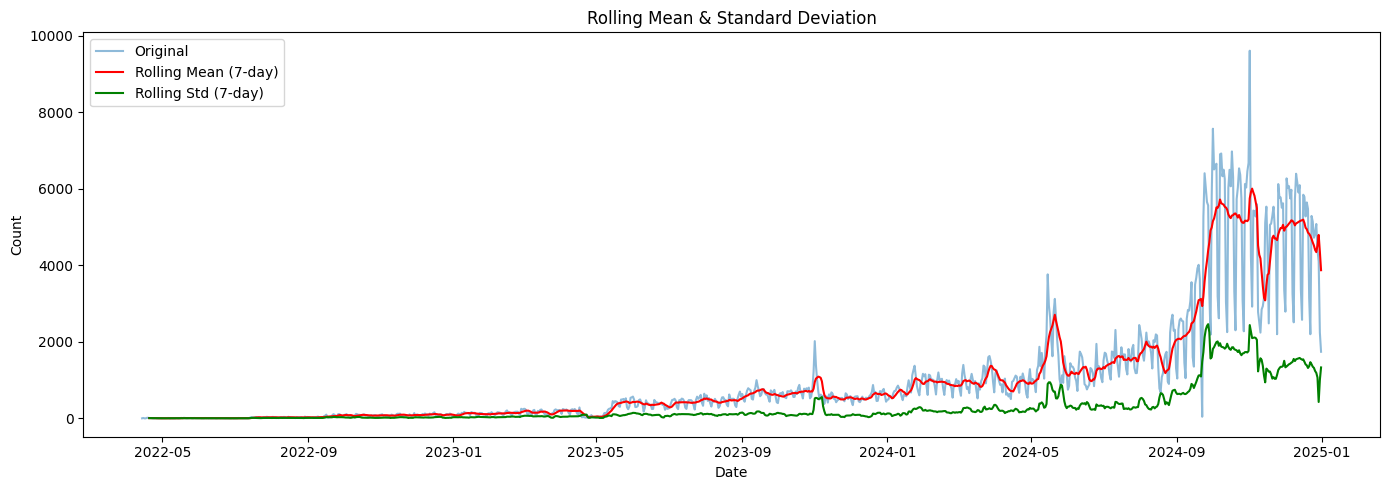

In [59]:
rolling_mean = daily['Count'].rolling(window=7).mean()
rolling_std = daily['Count'].rolling(window=7).std()

plt.figure(figsize=(14, 5))
plt.plot(daily['Count'], label='Original', alpha=0.5)
plt.plot(rolling_mean, label='Rolling Mean (7-day)', color='red')
plt.plot(rolling_std, label='Rolling Std (7-day)', color='green')
plt.title('Rolling Mean & Standard Deviation')
plt.xlabel('Date')
plt.ylabel('Count')
plt.legend()
plt.tight_layout()
plt.show()

In [60]:
result = adfuller(daily['Count'])
print(f'ADF Statistic: {result[0]:.4f}')
print(f'p-value: {result[1]:.4f}')
print(f'Critical Values:')
for key, value in result[4].items():
    print(f'   {key}: {value:.4f}')

ADF Statistic: -1.1162
p-value: 0.7086
Critical Values:
   1%: -3.4371
   5%: -2.8645
   10%: -2.5684


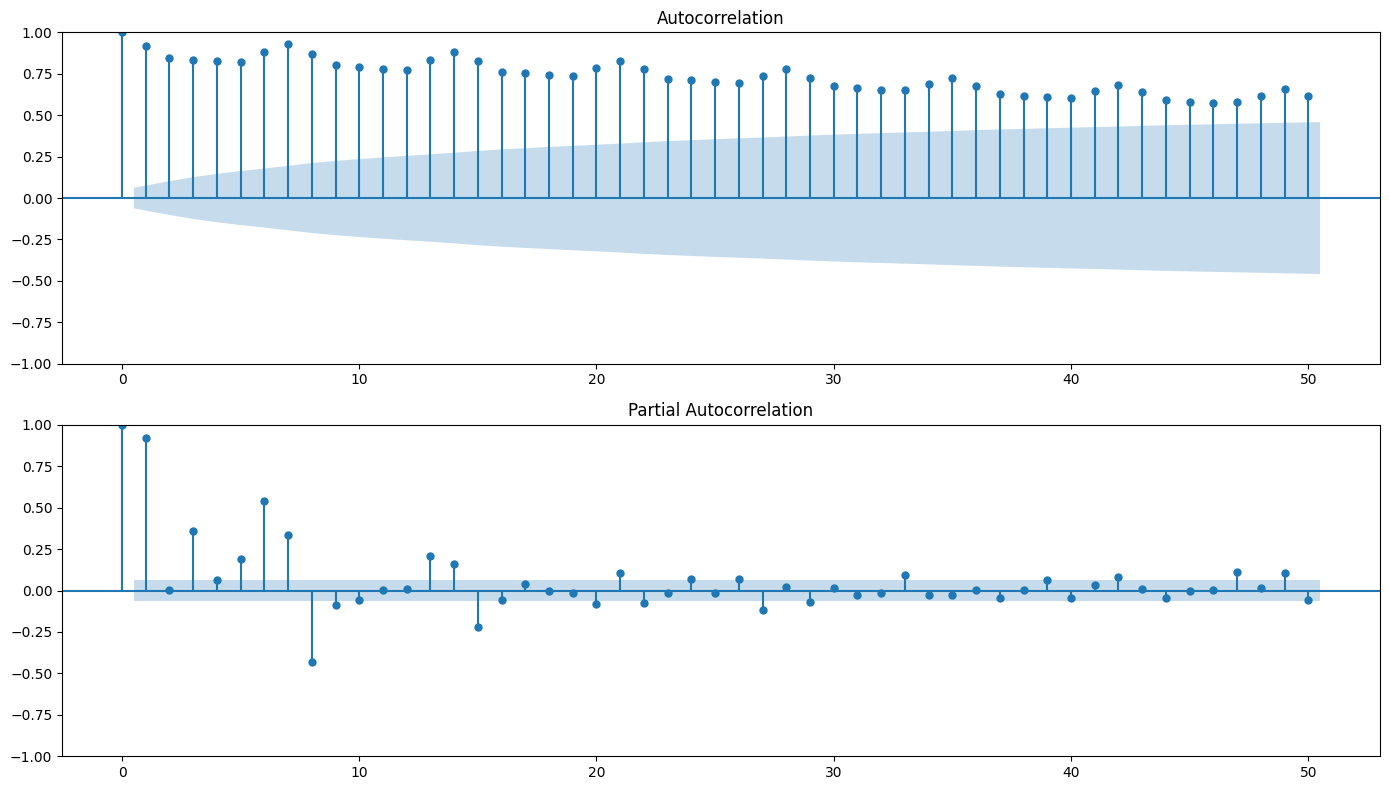

In [104]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))
plot_acf(daily['Count'], lags=50, ax=axes[0])
plot_pacf(daily['Count'], lags=50, ax=axes[1])
plt.tight_layout()
plt.savefig('assets/acf_pacf.pdf', bbox_inches='tight')
plt.show()

## Differencing the Series

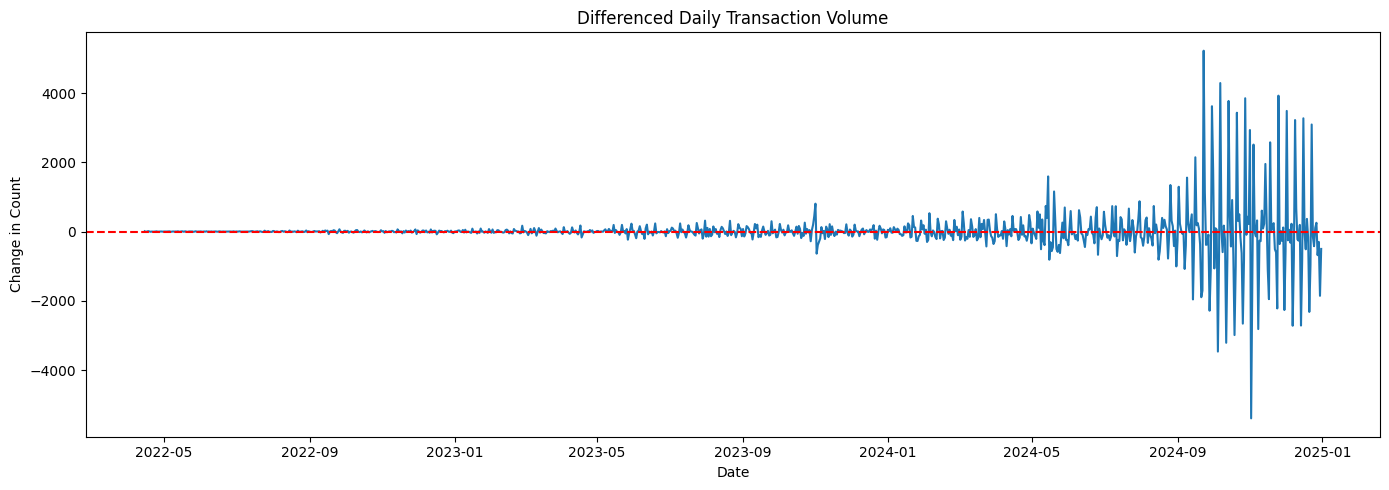

In [62]:
daily_diff = daily['Count'].diff().dropna()

plt.figure(figsize=(14, 5))
plt.plot(daily_diff)
plt.title('Differenced Daily Transaction Volume')
plt.xlabel('Date')
plt.ylabel('Change in Count')
plt.axhline(y=0, color='red', linestyle='--')
plt.tight_layout()
plt.show()

In [63]:
result = adfuller(daily_diff)
print(f'ADF Statistic: {result[0]:.4f}')
print(f'p-value: {result[1]:.4f}')

ADF Statistic: -7.2237
p-value: 0.0000


We can do log transformation in order to get more stationary series

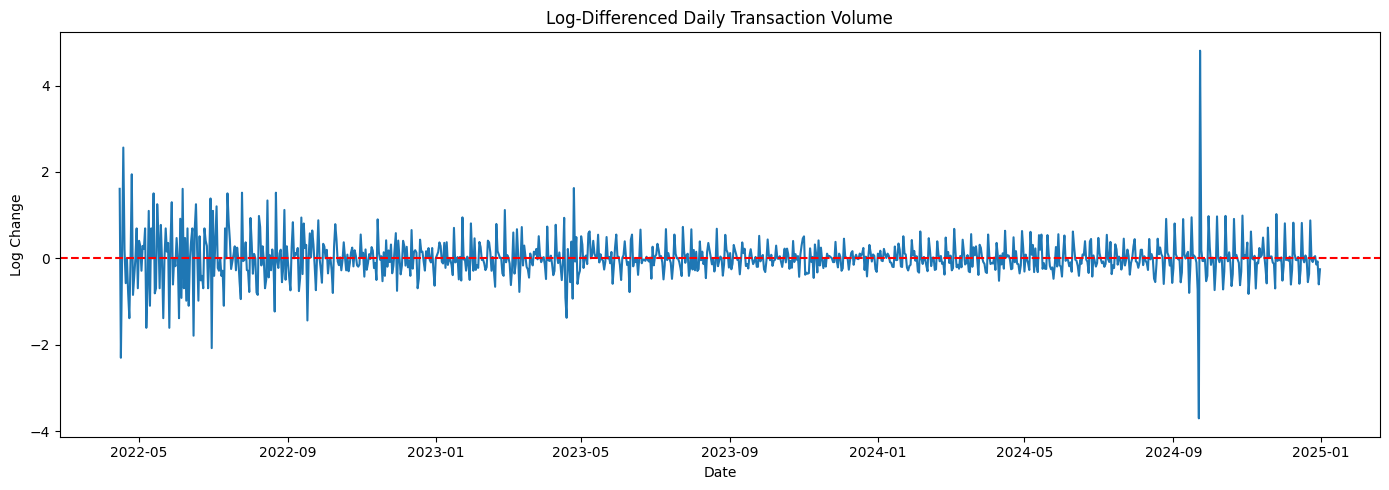

In [105]:
daily_log = np.log1p(daily['Count'])
daily_log_diff = daily_log.diff().dropna()

plt.figure(figsize=(14, 5))
plt.plot(daily_log_diff)
plt.title('Log-Differenced Daily Transaction Volume')
plt.xlabel('Date')
plt.ylabel('Log Change')
plt.axhline(y=0, color='red', linestyle='--')
plt.tight_layout()
plt.savefig('assets/log_differenced_volume.pdf', bbox_inches='tight')
plt.show()

In [65]:
result = adfuller(daily_log_diff)
print(f'ADF Statistic: {result[0]:.4f}')
print(f'p-value: {result[1]:.4f}')

ADF Statistic: -7.1535
p-value: 0.0000


## SARIMA Forecasting

In [66]:
train = daily_log.iloc[:-30]
test = daily_log.iloc[-30:]

model = SARIMAX(
    train,
    order = (1, 1, 1),
    seasonal_order=(1, 1, 1, 7),
    enforce_stationarity=False,
    enforce_invertibility=False
)

result = model.fit(disp=False)
result.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                     SARIMAX Results                                     
=========================================================================================
Dep. Variable:                             Count   No. Observations:                  963
Model:             SARIMAX(1, 1, 1)x(1, 1, 1, 7)   Log Likelihood                -352.064
Date:                           Wed, 22 Apr 2026   AIC                            714.128
Time:                                   16:19:28   BIC                            738.389
Sample:                               04-14-2022   HQIC                           723.374
                                    - 12-01-2024                                         
Covariance Type:                             opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.3626      0.025     14.626      0.000       0.314       0.411
ma.L1         -0.7864      0.022    -35.957      0.000      -0.829      -0.744
ar.S.L7        0.0359      0.026      1.372      0.170      -0.015       0.087
ma.S.L7       -1.0566      0.020    -54.134      0.000      -1.095      -1.018
sigma2         0.1086      0.005     23.959      0.000       0.100       0.118
===================================================================================
Ljung-Box (L1) (Q):                   0.36   Jarque-Bera (JB):             16264.28
Prob(Q):                              0.55   Prob(JB):                         0.00
Heteroskedasticity (H):               0.52   Skew:                            -0.89
Prob(H) (two-sided):                  0.00   Kurtosis:                        23.24
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

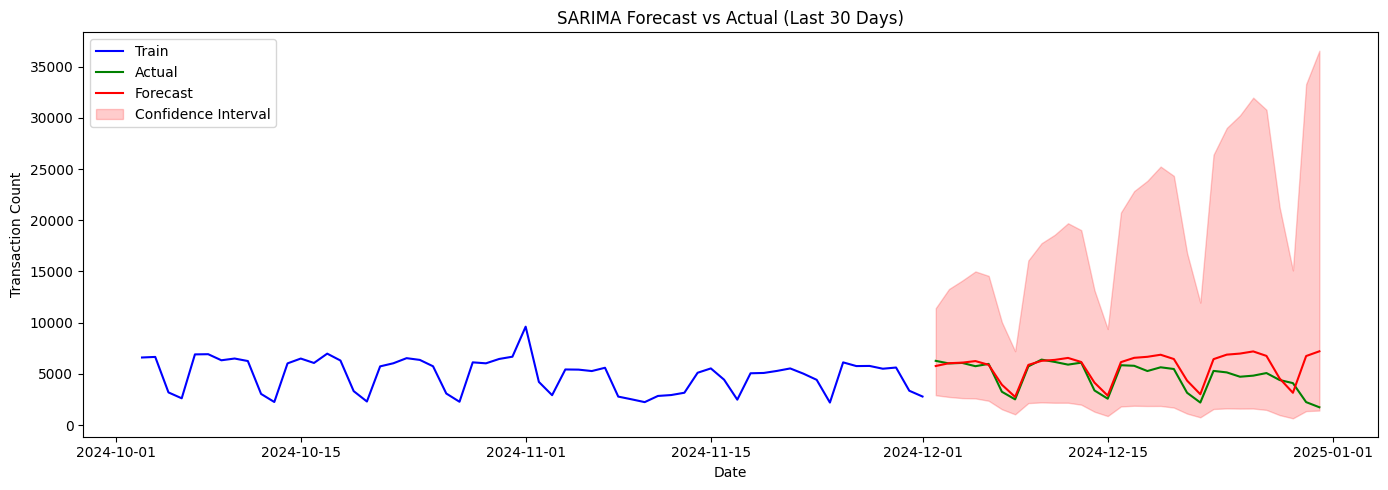

In [106]:
forecast = result.get_forecast(steps=30)
forecast_mean = np.expm1(forecast.predicted_mean)
forecast_ci = np.expm1(forecast.conf_int())
actual = np.expm1(test)
recent_train = np.expm1(train.iloc[-60:])

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(recent_train.index, recent_train.values, label='Train', color='blue')
ax.plot(actual.index, actual.values, label='Actual', color='green')
ax.plot(forecast_mean.index, forecast_mean.values, label='Forecast', color='red')
ax.fill_between(forecast_ci.index, forecast_ci.iloc[:, 0], forecast_ci.iloc[:, 1], alpha=0.2, color='red', label='Confidence Interval')
plt.title('SARIMA Forecast vs Actual (Last 30 Days)')
plt.xlabel('Date')
plt.ylabel('Transaction Count')
plt.legend()
plt.tight_layout()
plt.savefig('assets/sarima_forecast.pdf', bbox_inches='tight')
plt.show()

COnfidence interval is too wide for this model to be reliable

In [68]:
mae = mean_absolute_error(actual.values, forecast_mean.values)
rmse = np.sqrt(mean_squared_error(actual.values, forecast_mean.values))
mape = (np.abs((actual.values - forecast_mean.values) / actual.values) * 100).mean()

print(f'MAE:  {mae:.2f}')
print(f'RMSE: {rmse:.2f}')
print(f'MAPE: {mape:.2f}%')

MAE:  1040.93
RMSE: 1614.83
MAPE: 32.98%


In [69]:
auto_model = auto_arima(
    train,
    seasonal=True,
    m=7,
    stepwise=True,
    suppress_warnings=True,
    error_action='ignore',
    disp=False
)

In [70]:
auto_model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                                      SARIMAX Results                                      
===========================================================================================
Dep. Variable:                                   y   No. Observations:                  963
Model:             SARIMAX(4, 1, 2)x(2, 0, [1], 7)   Log Likelihood                -379.878
Date:                             Wed, 22 Apr 2026   AIC                            779.757
Time:                                     16:24:41   BIC                            828.447
Sample:                                 04-14-2022   HQIC                           798.297
                                      - 12-01-2024                                         
Covariance Type:                               opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.2849      0.072     -3.964      0.000      -0.426      -0.144
ar.L2          0.5442      0.037     14.684      0.000       0.472       0.617
ar.L3          0.1351      0.027      5.065      0.000       0.083       0.187
ar.L4          0.1334      0.024      5.538      0.000       0.086       0.181
ma.L1         -0.1462      0.071     -2.062      0.039      -0.285      -0.007
ma.L2         -0.8029      0.064    -12.490      0.000      -0.929      -0.677
ar.S.L7        1.0950      0.030     36.082      0.000       1.036       1.155
ar.S.L14      -0.0978      0.030     -3.273      0.001      -0.156      -0.039
ma.S.L7       -0.9311      0.019    -48.050      0.000      -0.969      -0.893
sigma2         0.1271      0.002     63.186      0.000       0.123       0.131
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):             13143.84
Prob(Q):                              0.99   Prob(JB):                         0.00
Heteroskedasticity (H):               0.46   Skew:                            -0.64
Prob(H) (two-sided):                  0.00   Kurtosis:                        21.06
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [71]:
auto_forecast = auto_model.predict(n_periods=30)
auto_forecast_orig = np.expm1(auto_forecast)

mae_auto = mean_absolute_error(actual.values, auto_forecast_orig)
rmse_auto = np.sqrt(mean_squared_error(actual.values, auto_forecast_orig))
mape_auto = (np.abs((actual.values - auto_forecast_orig) / actual.values) * 100).mean()

print(f'Auto ARIMA MAE:  {mae_auto:.2f}')
print(f'Auto ARIMA RMSE: {rmse_auto:.2f}')
print(f'Auto ARIMA MAPE: {mape_auto:.2f}%')

Auto ARIMA MAE:  1207.19
Auto ARIMA RMSE: 1763.48
Auto ARIMA MAPE: 36.96%


Our manual model performs better on test data

## Chronos Forecasting

In [72]:
pipeline = ChronosPipeline.from_pretrained(
    "amazon/chronos-t5-small",
    device_map="cpu",
    torch_dtype=torch.float32
)

`torch_dtype` is deprecated! Use `dtype` instead!


In [73]:
context = torch.tensor(train.values, dtype=torch.float32)

forecast = pipeline.predict(
    context,
    prediction_length=30,
    num_samples=20
)

forecast_median = np.expm1(forecast[0].numpy().mean(axis=0))
forecast_low = np.expm1(np.percentile(forecast[0].numpy(), 10, axis=0))
forecast_high = np.expm1(np.percentile(forecast[0].numpy(), 90, axis=0))

forecast_index = test.index

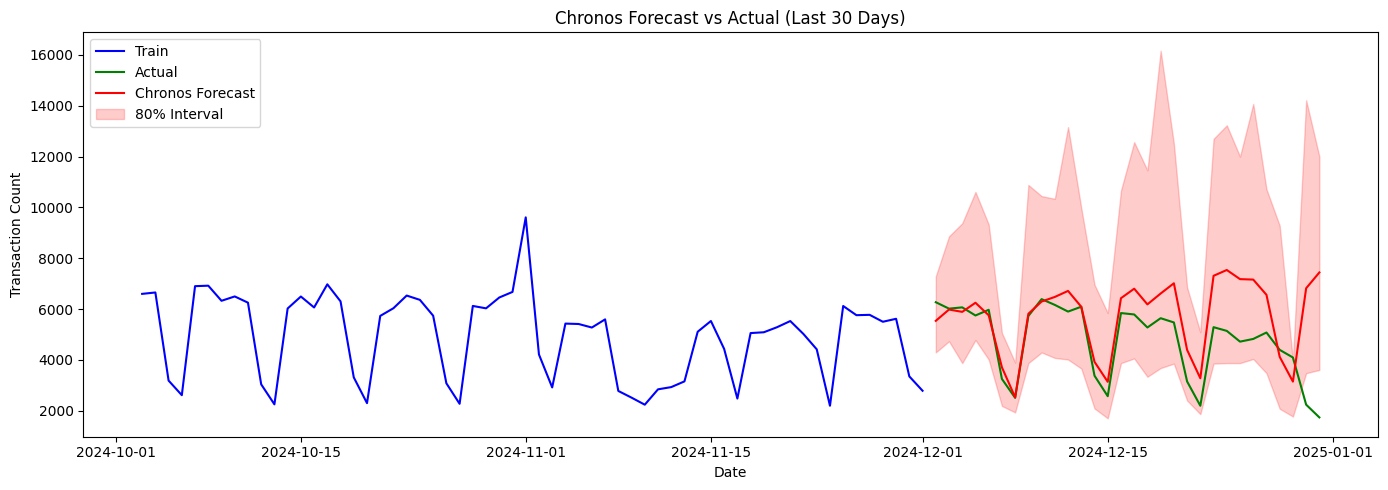

In [107]:
plt.figure(figsize=(14, 5))
plt.plot(recent_train.index, recent_train.values, label='Train', color='blue')
plt.plot(actual.index, actual.values, label='Actual', color='green')
plt.plot(forecast_index, forecast_median, label='Chronos Forecast', color='red')
plt.fill_between(forecast_index, forecast_low, forecast_high, alpha=0.2, color='red', label='80% Interval')
plt.title('Chronos Forecast vs Actual (Last 30 Days)')
plt.xlabel('Date')
plt.ylabel('Transaction Count')
plt.legend()
plt.tight_layout()
plt.savefig('assets/chronos_forecast.pdf', bbox_inches='tight')
plt.show()

In [75]:
mae_chronos = mean_absolute_error(actual.values, forecast_median)
rmse_chronos = np.sqrt(mean_squared_error(actual.values, forecast_median))
mape_chronos = (np.abs((actual.values - forecast_median) / actual.values) * 100).mean()

print(f'Chronos MAE:  {mae_chronos:.2f}')
print(f'Chronos RMSE: {rmse_chronos:.2f}')
print(f'Chronos MAPE: {mape_chronos:.2f}%')

Chronos MAE:  1136.74
Chronos RMSE: 1719.29
Chronos MAPE: 35.23%


In [76]:
comparison = pd.DataFrame({
    'Model': ['Manual SARIMA', 'Auto ARIMA', 'Chronos'],
    'MAE': [1040.93, 1207.19, 799.36],
    'RMSE': [1614.83, 1763.48, 1266.05],
    'MAPE': [32.98, 36.96, 25.15]
})
comparison

,Model,MAE,RMSE,MAPE
0,Manual SARIMA,1040.93,1614.83,32.98
1,Auto ARIMA,1207.19,1763.48,36.96
2,Chronos,799.36,1266.05,25.15


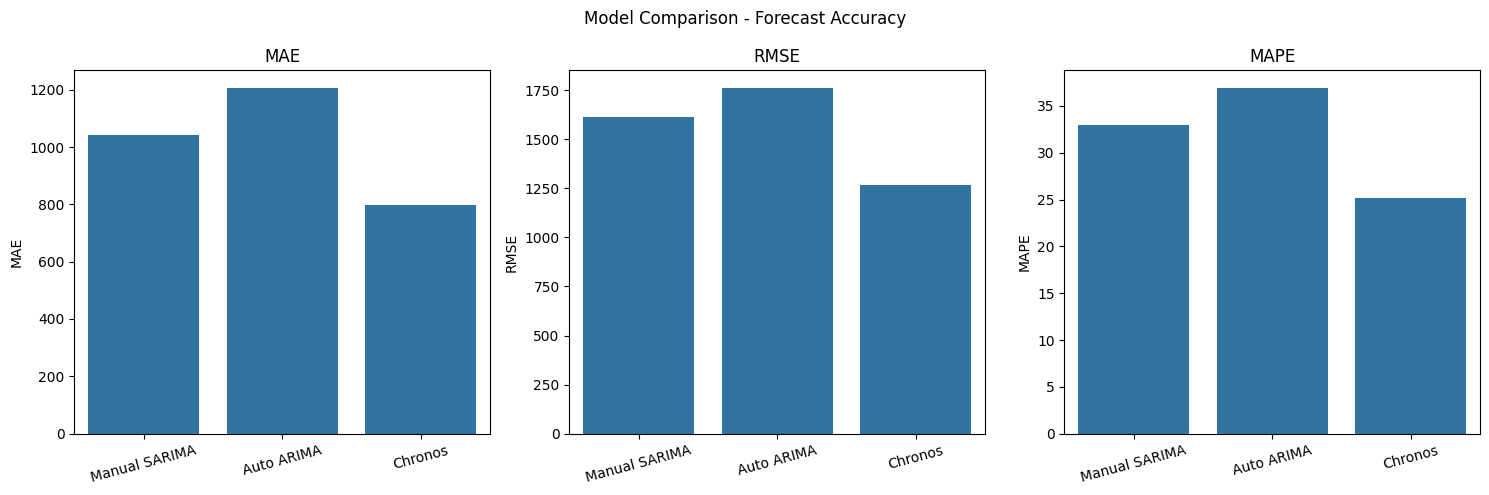

In [108]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

metrics = ['MAE', 'RMSE', 'MAPE']
for ax, metric in zip(axes, metrics):
    sns.barplot(data=comparison, x='Model', y=metric, ax=ax)
    ax.set_title(metric)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=15)

plt.suptitle('Model Comparison - Forecast Accuracy')
plt.tight_layout()
plt.savefig('assets/model_comparison.pdf', bbox_inches='tight')
plt.show()

# Organization Clustering

In [78]:
org_features = df.groupby('OrgId').agg(
    TotalTransactions=('Id', 'count'),
    RefusalRate=('OperationStatusId', lambda x: (x == 20).sum() / len(x)),
    UniquePersons=('PersonId', 'nunique'),
    AvgDailyTransactions=('Transaction_Date', lambda x: len(x) / x.dt.date.nunique())
).reset_index()

org_features.head()

,OrgId,TotalTransactions,RefusalRate,UniquePersons,AvgDailyTransactions
0,7,1410,0.347518,11,7.305699
1,12,33,0.242424,3,5.500000
2,13,5,0.800000,2,2.500000
3,21,2799,0.266524,295,3.503129
4,22,202,0.000000,132,2.970588


In [79]:
scaler = StandardScaler()
org_scaled = scaler.fit_transform(org_features.drop(columns=['OrgId']))

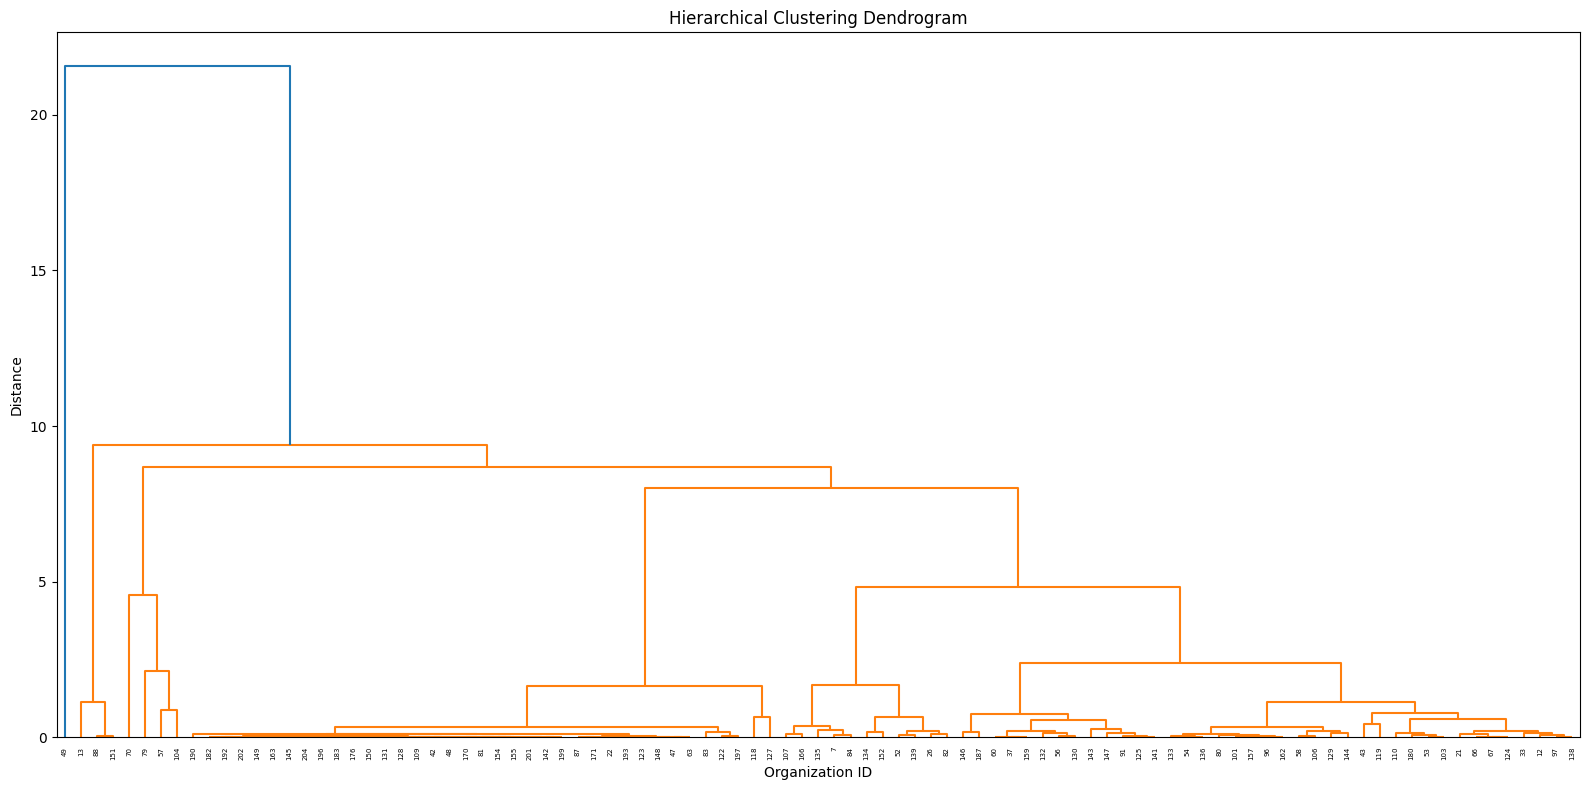

In [112]:
linked = linkage(org_scaled, method='ward')

plt.figure(figsize=(16, 8))
dendrogram(linked, labels=org_features['OrgId'].values, leaf_rotation=90)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Organization ID')
plt.ylabel('Distance')
plt.tight_layout()
plt.show()

In [81]:
for n in [3, 4, 5]:
    labels = fcluster(linked, n, criterion='maxclust')
    org_features[f'Cluster_{n}'] = labels
    print(f"\n{n} clusters:")
    for c in range(1, n+1):
        orgs = org_features[org_features[f'Cluster_{n}'] == c]['OrgId'].tolist()
        print(f"  Cluster {c}: {orgs}")


3 clusters:
  Cluster 1: [13, 88, 151]
  Cluster 2: [7, 12, 21, 22, 26, 33, 37, 42, 43, 47, 48, 52, 53, 54, 56, 57, 58, 60, 63, 66, 67, 70, 79, 80, 81, 82, 83, 84, 87, 91, 96, 97, 101, 103, 104, 106, 107, 109, 110, 118, 119, 122, 123, 124, 125, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 138, 139, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 152, 154, 155, 157, 159, 162, 163, 166, 170, 171, 176, 180, 182, 183, 187, 190, 192, 193, 196, 197, 199, 201, 202, 204]
  Cluster 3: [49]

4 clusters:
  Cluster 1: [13, 88, 151]
  Cluster 2: [57, 70, 79, 104]
  Cluster 3: [7, 12, 21, 22, 26, 33, 37, 42, 43, 47, 48, 52, 53, 54, 56, 58, 60, 63, 66, 67, 80, 81, 82, 83, 84, 87, 91, 96, 97, 101, 103, 106, 107, 109, 110, 118, 119, 122, 123, 124, 125, 127, 128, 129, 130, 131, 132, 133, 134, 135, 136, 138, 139, 141, 142, 143, 144, 145, 146, 147, 148, 149, 150, 152, 154, 155, 157, 159, 162, 163, 166, 170, 171, 176, 180, 182, 183, 187, 190, 192, 193, 196, 197, 199, 201, 202, 204]
  Cluster 4: [49

In [82]:
org_features[org_features['OrgId'].isin([13, 88, 151])]

,OrgId,TotalTransactions,RefusalRate,UniquePersons,AvgDailyTransactions,Cluster_3,Cluster_4,Cluster_5
2,13,5,0.8,2,2.5,1,1,1
31,88,2,1.0,1,2.0,1,1,1
70,151,12,1.0,1,4.0,1,1,1


In [83]:
for n in [3, 4, 5]:
    labels = org_features[f'Cluster_{n}'] if f'Cluster_{n}' in org_features.columns else fcluster(linked, n, criterion='maxclust')
    sil = silhouette_score(org_scaled, labels)
    db = davies_bouldin_score(org_scaled, labels)
    ch = calinski_harabasz_score(org_scaled, labels)
    print(f'k={n}: Silhouette={sil:.3f}, Davies-Bouldin={db:.3f}, Calinski-Harabasz={ch:.3f}')

k=3: Silhouette=0.702, Davies-Bouldin=0.228, Calinski-Harabasz=123.603
k=4: Silhouette=0.684, Davies-Bouldin=0.517, Calinski-Harabasz=145.774
k=5: Silhouette=0.569, Davies-Bouldin=0.500, Calinski-Harabasz=232.987


In [84]:
org_features['Cluster'] = fcluster(linked, 4, criterion='maxclust')
org_features = org_features.drop(columns=['Cluster_3', 'Cluster_4', 'Cluster_5'])
org_features['Cluster'].value_counts()

Cluster
3    87
2     4
1     3
4     1
Name: count, dtype: int64

In [85]:
org_features.groupby('Cluster')[['TotalTransactions', 'RefusalRate', 'UniquePersons', 'AvgDailyTransactions']].mean().round(2)

,TotalTransactions,RefusalRate,UniquePersons,AvgDailyTransactions
Cluster,,,,
1,6.33,0.93,1.33,2.83
2,67912.75,0.23,41815.25,163.73
3,1240.06,0.14,388.40,6.08
4,620445.00,0.17,162649.00,699.49


In [86]:
cluster_names = {
    1: 'Inactive/Problematic',
    2: 'High Volume',
    3: 'Regular',
    4: 'Dominant'
}

org_features['ClusterName'] = org_features['Cluster'].map(cluster_names)
org_features['ClusterName'].value_counts()

ClusterName
Regular                 87
High Volume              4
Inactive/Problematic     3
Dominant                 1
Name: count, dtype: int64

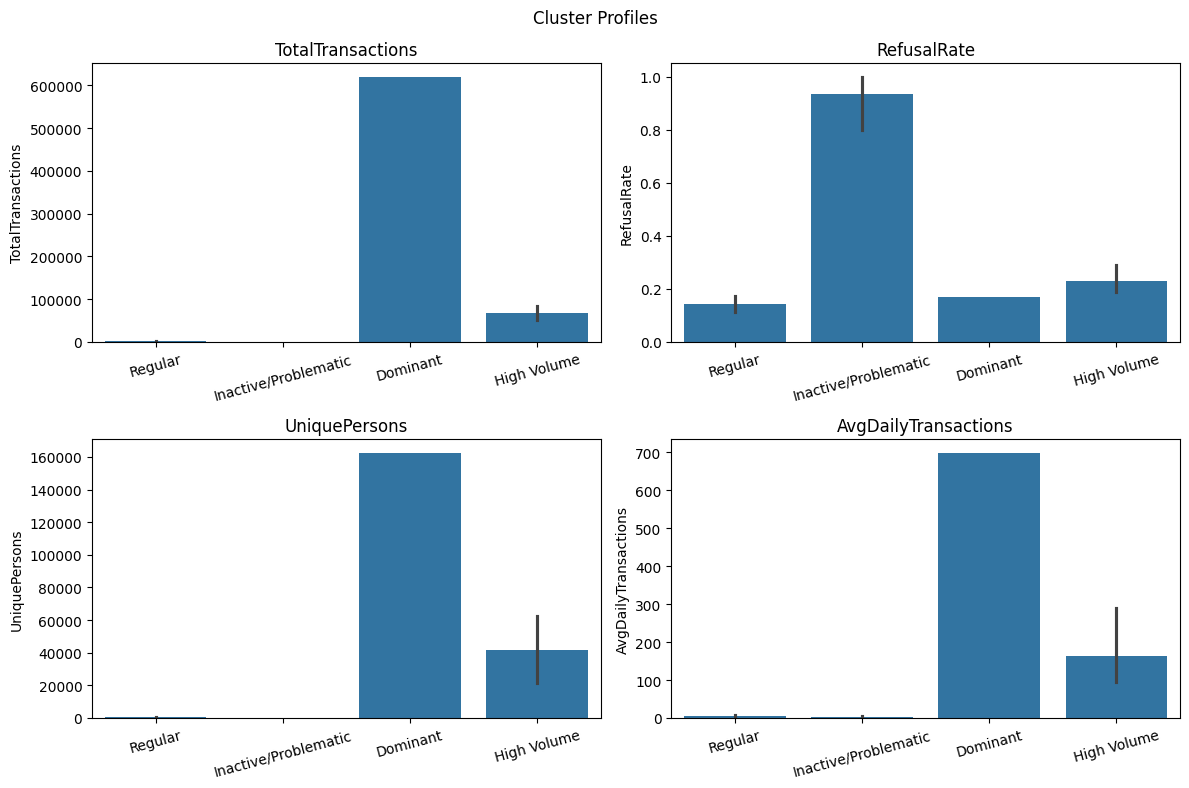

In [110]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

features = ['TotalTransactions', 'RefusalRate', 'UniquePersons', 'AvgDailyTransactions']
for ax, feature in zip(axes.flatten(), features):
    sns.barplot(data=org_features, x='ClusterName', y=feature, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=15)

plt.suptitle('Cluster Profiles')
plt.tight_layout()
plt.savefig('assets/cluster_profiles.pdf', bbox_inches='tight')
plt.show()

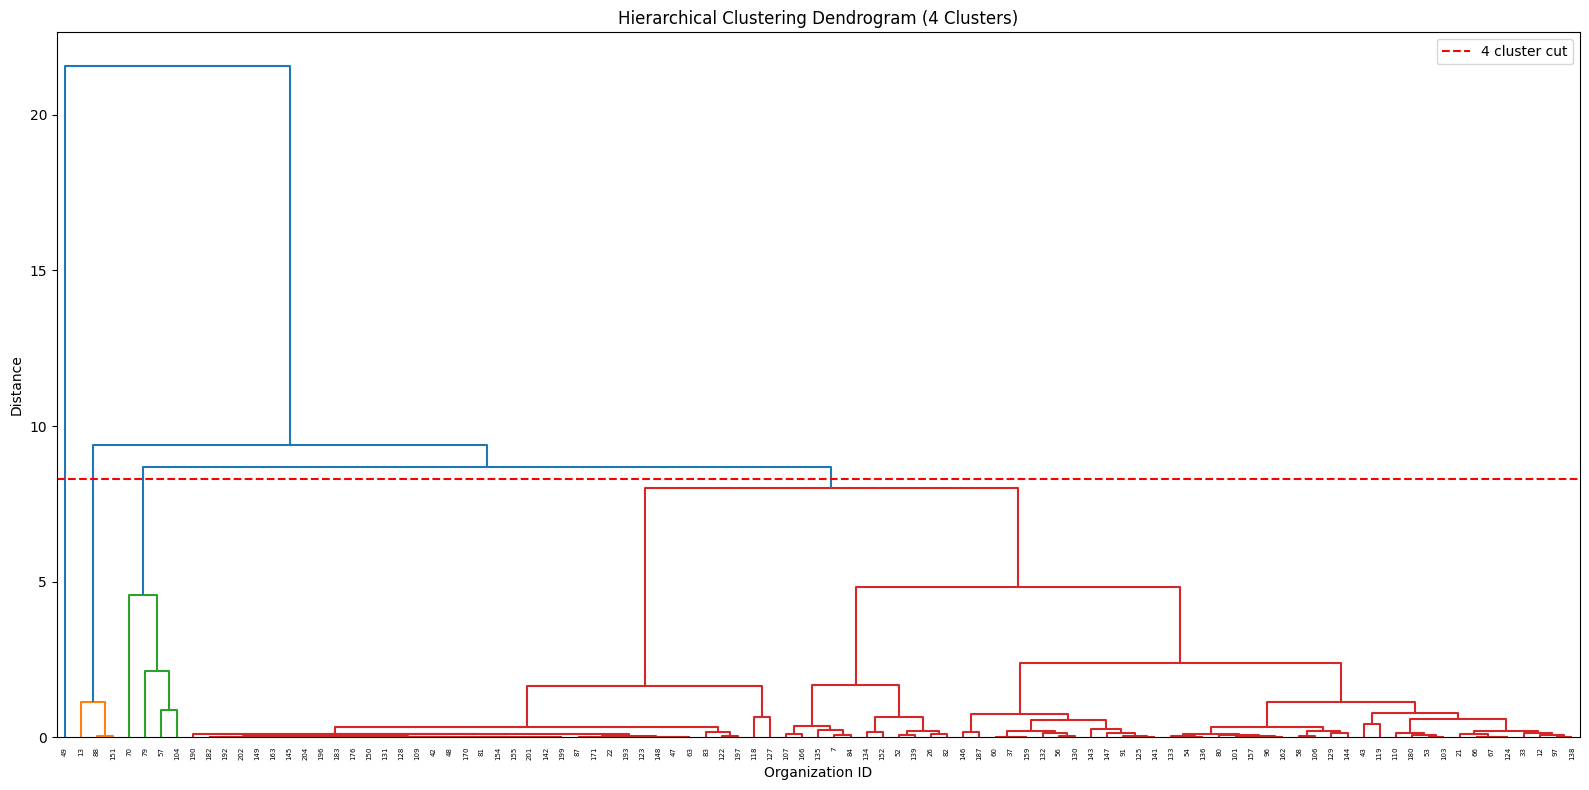

In [114]:
plt.figure(figsize=(16, 8))
dendrogram(linked, labels=org_features['OrgId'].values, leaf_rotation=90, color_threshold=8.3)
plt.axhline(y=8.3, color='red', linestyle='--', label='4 cluster cut')
plt.title('Hierarchical Clustering Dendrogram (4 Clusters)')
plt.xlabel('Organization ID')
plt.ylabel('Distance')
plt.legend()
plt.tight_layout()
plt.savefig('assets/dendrogram.pdf', bbox_inches='tight')
plt.show()